# Time-series forecasting with a bidirectional LSTM + 1-D convolution

University deep-learning course challenge (*Artificial Neural Networks and Deep Learning*, 2023, team of four): forecast the next samples of **48 000 univariate time series** (6 categories, length up to 2 776,
each with its own valid start index).

**Approach**
* Per-series min-max normalisation; sliding windows of 200 past samples (stride 5 or 10) with a forecast horizon
  ("telescope") of 9 steps for **direct** multi-step forecasting or 3 steps for **autoregressive** forecasting
  (predict 3, append, repeat until 18 steps — see `submission_model.py`).
* Model: Bidirectional LSTM(64) → Conv1D(128, k=3, ReLU) → Conv1D(1, k=3) → crop to the horizon;
  MSE loss, Adam, early stopping (patience 12) and LR reduction on plateau.

**Results** (hidden test set of the challenge, as reported in the team's report — the platform scores are not
in the notebook outputs):

| Model | Window / stride / horizon | Test MSE |
|---|---|---|
| Direct | 200 / 10 / 9 | 0.00740 |
| Direct | 200 / 5 / 9 | 0.00674 |
| **Autoregressive** | 200 / 5 / 3 (→ 18) | **0.00536** |
| Conv1D before the BiLSTM (32 filters) | — | 0.00710 |

The training log below (direct model, horizon 9) reaches a validation MSE of 0.0049 before the run was stopped
manually at epoch 49.

**Data:** the challenge's `training_data.npy`, `valid_periods.npy`, `categories.npy` are not redistributed.


In [ ]:
import os

# Root folder of the dataset(s) used in this notebook.
# Set the DATA_ROOT environment variable or edit the default below.
# On Google Colab you can first mount Drive with:
#   from google.colab import drive; drive.mount('/content/drive')
DATA_ROOT = os.environ.get("DATA_ROOT", "./data")

### Import libraries

In [ ]:
# Fix randomness and hide warnings
seed = 42

import os
os.environ['TF_CPP_MIN_LOG_LEVEL'] = '3'
os.environ['PYTHONHASHSEED'] = str(seed)
os.environ['MPLCONFIGDIR'] = os.getcwd()+'/configs/'

import warnings
warnings.simplefilter(action='ignore', category=FutureWarning)
warnings.simplefilter(action='ignore', category=Warning)
from tqdm import tqdm
import numpy as np
np.random.seed(seed)

import logging

import random
random.seed(seed)

In [ ]:
# Import tensorflow
import tensorflow as tf
from tensorflow import keras as tfk
from tensorflow.keras import layers as tfkl
tf.autograph.set_verbosity(0)
tf.get_logger().setLevel(logging.ERROR)
tf.compat.v1.logging.set_verbosity(tf.compat.v1.logging.ERROR)
tf.random.set_seed(seed)
tf.compat.v1.set_random_seed(seed)
print(tf.__version__)

2.15.0


In [ ]:
import pandas as pd
import seaborn as sns
from datetime import datetime
import matplotlib.pyplot as plt
plt.rc('font', size=16)
from sklearn.preprocessing import MinMaxScaler

### Load and process data

In [ ]:
training_data = np.load(os.path.join(DATA_ROOT, 'training_data.npy'))
valid_periods = np.load(os.path.join(DATA_ROOT, 'valid_periods.npy'))
categories = np.load(os.path.join(DATA_ROOT, 'categories.npy'))

In [ ]:
valid_periods.T[0].max()

2752

In [ ]:
valid_periods.T[0].mean()

2577.6997708333333

In [ ]:
valid_periods.T[0].min()

0

In [ ]:
training_dataframe= pd.DataFrame(training_data.T)
valid_periods_dataframe= pd.DataFrame(valid_periods.T)
categories_dataframe= pd.DataFrame(categories)

In [ ]:
print(training_dataframe.shape)
training_dataframe.tail()

(2776, 48000)


         0      1         2         3         4         5         6      \
2771  0.640741  0.640  0.932531  0.486370  0.704545  0.673469  0.841492   
2772  0.516667  0.536  0.955206  0.450502  0.863636  0.653061  0.878788   
2773  0.602778  0.600  0.960481  0.470588  0.727273  0.653061  0.841492   
2774  0.367593  0.460  0.946506  0.569584  0.818182  0.632653  0.841492   
2775  0.331481  0.396  0.977140  0.571019  0.840909  0.642857  0.834499   

        7         8         9      ...     47990     47991     47992  \
2771  0.82875  0.119403  0.107014  ...  0.082809  0.749190  0.732024   
2772  0.86250  0.130258  0.098921  ...  0.072276  0.824082  0.701938   
2773  0.86250  0.124830  0.098022  ...  0.071384  0.898371  0.783550   
2774  0.87625  0.132972  0.091727  ...  0.071545  0.048314  0.808614   
2775  0.89500  0.104478  0.095324  ...  0.081005  0.129289  0.893487   

         47993     47994     47995     47996     47997     47998     47999  
2771  0.653406  0.733459  0.319784  0.4

In [ ]:
print(valid_periods_dataframe.shape)
valid_periods_dataframe.head()

(2, 48000)


   0      1      2      3      4      5      6      7      8      9      ...  \
0   2325   2325   2325   2712   2682   2128   2682   2682   1972   2428  ...   
1   2776   2776   2776   2776   2776   2776   2776   2776   2776   2776  ...   

   47990  47991  47992  47993  47994  47995  47996  47997  47998  47999  
0   2627   2678   2687   2678   2678   2642   2642   2676   2676   2676  
1   2776   2776   2776   2776   2776   2776   2776   2776   2776   2776  

[2 rows x 48000 columns]

In [ ]:
print(categories_dataframe.shape)
categories_dataframe.head()

(48000, 1)


   0
0  D
1  D
2  D
3  D
4  D

In [ ]:
training_dataframe.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2776 entries, 0 to 2775
Columns: 48000 entries, 0 to 47999
dtypes: float64(48000)
memory usage: 1016.6 MB


In [ ]:
valid_periods_dataframe.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2 entries, 0 to 1
Columns: 48000 entries, 0 to 47999
dtypes: int64(48000)
memory usage: 750.1 KB


In [ ]:
categories_dataframe.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 48000 entries, 0 to 47999
Data columns (total 1 columns):
 #   Column  Non-Null Count  Dtype 
---  ------  --------------  ----- 
 0   0       48000 non-null  object
dtypes: object(1)
memory usage: 375.1+ KB


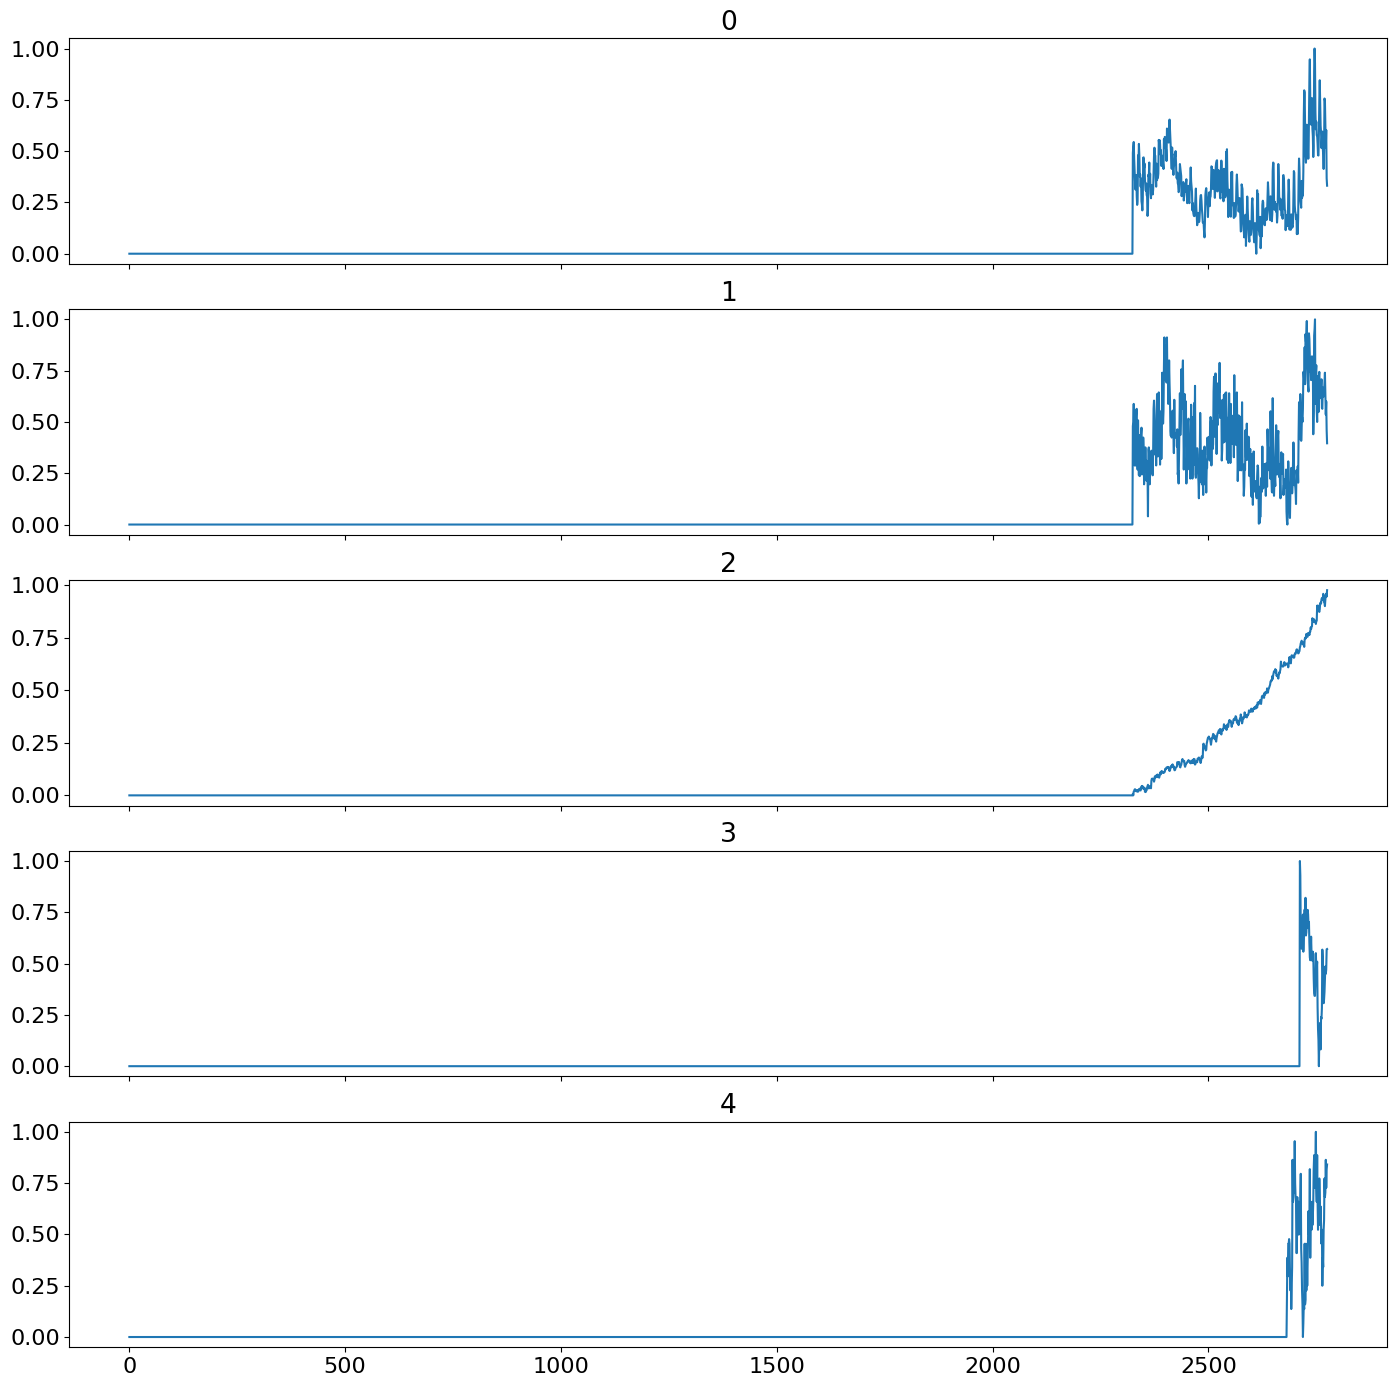

In [ ]:
def inspect_dataframe(df, columns):
    figs, axs = plt.subplots(len(columns), 1, sharex=True, figsize=(17,17))
    for i, col in enumerate(columns):
        axs[i].plot(df[col])
        axs[i].set_title(col)
    plt.show()
inspect_dataframe(training_dataframe, training_dataframe.columns[:5])

### Normalisation

In [ ]:
X_train_raw = training_dataframe


# Normalize both features and labels
X_min = X_train_raw.min()
X_max = X_train_raw.max()

X_train_raw = (X_train_raw-X_min)/(X_max-X_min)

In [ ]:
window = 200
stride = 5

In [ ]:
def build_sequences(df, valid_periods, window, stride, telescope):
    """Cut every series (one column of `df`) into (window -> telescope) training pairs."""
    assert window % stride == 0
    dataset = []
    labels = []
    for i in tqdm(range(df.shape[1])):
        # valid part of the i-th series
        temp_df = df.iloc[valid_periods[i][0]:, i].values.astype('float32')
        if len(temp_df) < window:
            # left-pad short series with zeros so that at least one window fits
            padding = np.zeros(window - len(temp_df), dtype='float32')
            temp_df = np.concatenate((padding, temp_df))
            assert len(temp_df) == window
        for idx in np.arange(0, len(temp_df) - window - telescope, stride):
            dataset.append(temp_df[idx:idx + window])
            labels.append(temp_df[idx + window:idx + window + telescope])

    dataset = np.array(dataset)
    labels = np.array(labels)
    return dataset, labels

### Direct multi-step forecasting

In [ ]:
telescope = 9  # forecast horizon of the direct model (the autoregressive model uses 3)
direct_telescope = telescope

In [ ]:
# Building the sequences for all 48 000 series is memory-hungry: cache them once and reload later.
X_train, y_train = build_sequences(X_train_raw, valid_periods, window, stride, direct_telescope)
np.save('forecast_x_train.npy', X_train)
np.save('forecast_y_train.npy', y_train)
X_train.shape, y_train.shape

In [ ]:
# X_train = np.load('forecast_x_train.npy')
# y_train = np.load('forecast_y_train.npy')

Reshape to (samples, time steps, features) for the Keras model.

In [ ]:
X_train = X_train.reshape(X_train.shape[0], window, 1)
y_train = y_train.reshape(y_train.shape[0], direct_telescope, 1)

In [ ]:
X_train.shape,y_train.shape

((471462, 200, 1), (471462, 9, 1))

In [ ]:
input_shape = X_train.shape[1:]
output_shape = y_train.shape[1:]
batch_size = 256
epochs = 200

In [ ]:
input_shape

(200, 1)

In [ ]:
def build_CONV_LSTM_model(input_shape, output_shape):
    # Ensure the input time steps are at least as many as the output time steps
    assert input_shape[0] >= output_shape[0], "For this exercise we want input time steps to be >= of output time steps"

    # Define the input layer with the specified shape
    input_layer = tfkl.Input(shape=input_shape, name='input_layer')

    # Add a Bidirectional LSTM layer with 64 units
    x = tfkl.Bidirectional(tfkl.LSTM(64, return_sequences=True, name='lstm'), name='bidirectional_lstm')(input_layer)

    # Add a 1D Convolution layer with 128 filters and a kernel size of 3
    x = tfkl.Conv1D(128, 3, padding='same', activation='relu', name='conv')(x)

    # Add a final Convolution layer to match the desired output shape
    output_layer = tfkl.Conv1D(output_shape[1], 3, padding='same', name='output_layer')(x)

    # Calculate the size to crop from the output to match the output shape
    crop_size = output_layer.shape[1] - output_shape[0]

    # Crop the output to the desired length
    output_layer = tfkl.Cropping1D((0, crop_size), name='cropping')(output_layer)

    # Construct the model by connecting input and output layers
    model = tf.keras.Model(inputs=input_layer, outputs=output_layer, name='CONV_LSTM_model')

    # Compile the model with Mean Squared Error loss and Adam optimizer
    model.compile(loss=tf.keras.losses.MeanSquaredError(), optimizer=tf.keras.optimizers.Adam())

    return model

In [ ]:
model = build_CONV_LSTM_model(input_shape, output_shape)
model.summary()
try:
    tfk.utils.plot_model(model, expand_nested=True, show_shapes=True)  # needs pydot + graphviz
except ImportError:
    pass

Model: "CONV_LSTM_model"
_________________________________________________________________
 Layer (type)                Output Shape              Param #   
 input_layer (InputLayer)    [(None, 200, 1)]          0         
                                                                 
 bidirectional_lstm (Bidire  (None, 200, 128)          33792     
 ctional)                                                        
                                                                 
 conv (Conv1D)               (None, 200, 128)          49280     
                                                                 
 output_layer (Conv1D)       (None, 200, 1)            385       
                                                                 
 cropping (Cropping1D)       (None, 9, 1)              0         
                                                                 
Total params: 83457 (326.00 KB)
Trainable params: 83457 (326.00 KB)
Non-trainable params: 0 (0.00 Byte)
_____________

In [ ]:
# Train the model
history = model.fit(
    x = X_train,
    y = y_train,
    batch_size = batch_size,
    epochs = epochs,
    validation_split=.1,
    callbacks = [
        tfk.callbacks.EarlyStopping(monitor='val_loss', mode='min', patience=12, restore_best_weights=True),
        tfk.callbacks.ReduceLROnPlateau(monitor='val_loss', mode='min', patience=10, factor=0.1, min_lr=1e-5)
    ]
).history

Epoch 1/200
6630/6630 [==============================] - 128s 18ms/step - loss: 0.0545 - val_loss: 0.0369 - lr: 0.0010
Epoch 2/200
6630/6630 [==============================] - 114s 17ms/step - loss: 0.0455 - val_loss: 0.0727 - lr: 0.0010
Epoch 3/200
6630/6630 [==============================] - 116s 18ms/step - loss: 0.0242 - val_loss: 0.0078 - lr: 0.0010
Epoch 4/200
6630/6630 [==============================] - 114s 17ms/step - loss: 0.0094 - val_loss: 0.0067 - lr: 0.0010
Epoch 5/200
6630/6630 [==============================] - 116s 17ms/step - loss: 0.0085 - val_loss: 0.0084 - lr: 0.0010
Epoch 6/200
6630/6630 [==============================] - 113s 17ms/step - loss: 0.0081 - val_loss: 0.0062 - lr: 0.0010
... [65 lines of log omitted] ...
6630/6630 [==============================] - 117s 18ms/step - loss: 0.0067 - val_loss: 0.0052 - lr: 0.0010
Epoch 40/200
6630/6630 [==============================] - 114s 17ms/step - loss: 0.0066 - val_loss: 0.0054 - lr: 0.0010
Epoch 41/200
6630/6630 [=

In [ ]:
best_epoch = np.argmin(history['val_loss'])
plt.figure(figsize=(17,4))
plt.plot(history['loss'], label='Training loss', alpha=.8, color='#ff7f0e')
plt.plot(history['val_loss'], label='Validation loss', alpha=.9, color='#5a9aa5')
plt.axvline(x=best_epoch, label='Best epoch', alpha=.3, ls='--', color='#5a9aa5')
plt.title('Mean Squared Error')
plt.legend()
plt.grid(alpha=.3)
plt.show()

plt.figure(figsize=(18,3))
plt.plot(history['lr'], label='Learning Rate', alpha=.8, color='#ff7f0e')
plt.axvline(x=best_epoch, label='Best epoch', alpha=.3, ls='--', color='#5a9aa5')
plt.legend()
plt.grid(alpha=.3)
plt.show()

In [ ]:
model.save('direct_forecasting_model.keras')